# Session 9 demo — Worked code for chi-square, Mann–Whitney, and correlation

Revision ID: S09-demo-r1  
Estimated time: 15–20 minutes

This notebook shows the Python pattern behind the Session 9 slides. It uses **different questions** from the graded practice (S09-E1–E3), so you can copy the pattern but still need to complete the exercises yourself. It uses the same synthetic dataset: download `deployment_benchmarks.csv` from the Session 9 page and keep it next to this notebook (or upload it in Colab).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

benchmark = pd.read_csv("deployment_benchmarks.csv")
independent = benchmark.loc[benchmark["design"] == "independent"].copy()

# Teaching grouping: split independent cases at the median LOC.
independent["loc_group"] = (independent["loc"] > independent["loc"].median()).map(
    {True: "high LOC", False: "low LOC"})
print(f"Independent rows: {len(independent)}")

Independent rows: 160


## 1. Chi-square test of independence

**Question:** Is passing the test associated with having high or low LOC?  
$H_0$: LOC group and pass/fail are independent. $H_A$: they are associated.

The slides use no continuity correction for a 2×2 table, so we set `correction=False`. Degrees of freedom are $(r-1)(c-1)$.

In [2]:
table = pd.crosstab(independent["loc_group"], independent["passed"])
display(table)

chi2, p_value, dof, expected = stats.chi2_contingency(table, correction=False)
print(f"chi2({dof}) = {chi2:.3f}, p = {p_value:.3f}")
print("Expected counts:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns).round(1))

n = table.to_numpy().sum()
cramers_v = (chi2 / (n * (min(table.shape) - 1))) ** 0.5
print(f"Cramer's V = {cramers_v:.3f}")

passed,False,True
loc_group,,
high LOC,12,68
low LOC,9,71


chi2(1) = 0.493, p = 0.482
Expected counts:


passed,False,True
loc_group,,
high LOC,10.5,69.5
low LOC,10.5,69.5


Cramer's V = 0.056


## 2. Mann–Whitney U for two independent groups

**Question:** Among baseline runs, do high-LOC and low-LOC cases have different response-time distributions?  
$H_0$: the two distributions are identical. $H_A$: they differ.

SciPy returns $U_1$ for the first sample. The slides report the smaller of $U_1$ and $U_2 = n_1 n_2 - U_1$.

n = 40 and 40; U = 559, p = 0.0207


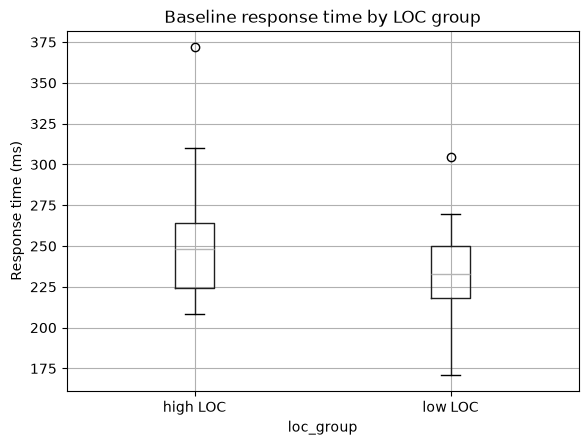

In [3]:
baseline = independent.loc[independent["version"] == "baseline"]
high = baseline.loc[baseline["loc_group"] == "high LOC", "response_time_ms"]
low = baseline.loc[baseline["loc_group"] == "low LOC", "response_time_ms"]

u1, p_value = stats.mannwhitneyu(high, low, alternative="two-sided")
u = min(u1, len(high) * len(low) - u1)
print(f"n = {len(high)} and {len(low)}; U = {u:.0f}, p = {p_value:.4f}")

baseline.boxplot(column="response_time_ms", by="loc_group")
plt.suptitle("")
plt.title("Baseline response time by LOC group")
plt.ylabel("Response time (ms)")
plt.show()

## 3. Pearson and Spearman correlation

**Question:** Among baseline runs, are cyclomatic complexity and response time associated?  
Pearson: $H_0$: $\rho_P = 0$, $H_A$: $\rho_P \ne 0$. Spearman: $H_0$: $\rho_S = 0$, $H_A$: $\rho_S \ne 0$.

Always inspect the plot first. Complexity is a discrete integer metric, so ties are expected.

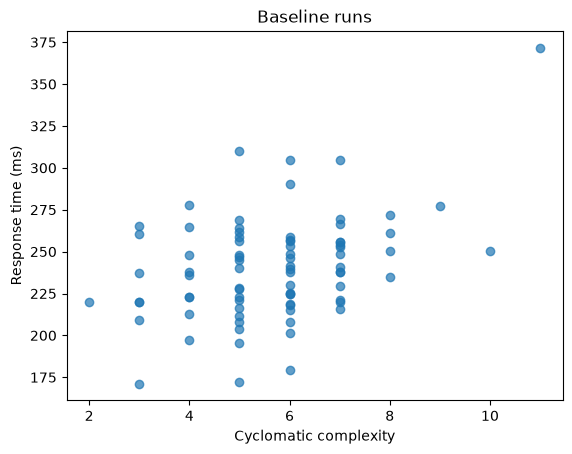

Pearson r = 0.400, p = 0.00023
Spearman rho = 0.293, p = 0.0083


In [4]:
plt.scatter(baseline["cyclomatic_complexity"], baseline["response_time_ms"], alpha=0.7)
plt.xlabel("Cyclomatic complexity")
plt.ylabel("Response time (ms)")
plt.title("Baseline runs")
plt.show()

pearson = stats.pearsonr(baseline["cyclomatic_complexity"], baseline["response_time_ms"])
spearman = stats.spearmanr(baseline["cyclomatic_complexity"], baseline["response_time_ms"])
print(f"Pearson r = {pearson.statistic:.3f}, p = {pearson.pvalue:.2g}")
print(f"Spearman rho = {spearman.statistic:.3f}, p = {spearman.pvalue:.2g}")

## 4. Wilcoxon signed-rank for paired data (pattern only)

The paired test is part of graded practice S09-E2, so no worked example is given here. The pattern is: pivot the paired cohort to one row per `case_id`, compute one difference per case, and pass the two matched columns to `stats.wilcoxon`. Do not use `mannwhitneyu` for paired measurements.

## What this demo does not show

These tests describe association in simulated data. They do not show that LOC or complexity causes latency, and they do not validate a predictive model.